In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os
import re
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

BASE_PATHS = {
    "NMF": Path("/home/moshtasa/Research/phd-recsys/Book/current/0420/NMF-0420/result/0420_NMF_bar_figures"),
    "SVD": Path("/home/moshtasa/Research/phd-recsys/Book/current/0420/SVD-0420/result/0420_SVD_bar_figures"),
}

def parse_txt(file_path):
    data = {}
    current_k = None

    with open(file_path, "r") as f:
        for line in f:
            line = line.strip()

            if line.startswith("k ="):
                current_k = int(line.split("=")[1].strip())
                data[current_k] = {}

            elif ":" in line and current_k is not None:
                match = re.match(r"(.*?)\:\s*([0-9.]+)", line)
                if match:
                    label = match.group(1).strip()
                    value = float(match.group(2))
                    data[current_k][label] = value

    return data

def generate_colors(n_list):
    cmap = plt.cm.get_cmap('tab20', len(n_list))
    return {n: cmap(i) for i, n in enumerate(n_list)}

def extract_genre(folder_name):
    parts = folder_name.lower().split("_")
    return parts[1] if len(parts) > 1 else None

nmf_map = {
    extract_genre(f): f
    for f in os.listdir(BASE_PATHS["NMF"])
    if (BASE_PATHS["NMF"] / f).is_dir()
}

svd_map = {
    extract_genre(f): f
    for f in os.listdir(BASE_PATHS["SVD"])
    if (BASE_PATHS["SVD"] / f).is_dir()
}

common_genres = sorted(set(nmf_map.keys()) & set(svd_map.keys()))
print("Detected genres:", common_genres)

# =========================
# MAIN LOOP
# =========================

for genre_key in common_genres:

    genre = genre_key.capitalize()

    nmf_folder = nmf_map[genre_key]
    svd_folder = svd_map[genre_key]

    paths = {
        "NMF": BASE_PATHS["NMF"] / nmf_folder,
        "SVD": BASE_PATHS["SVD"] / svd_folder,
    }

    parsed_data = {}

    for method, folder_path in paths.items():
        txt_files = [f for f in os.listdir(folder_path) if f.endswith(".txt")]
        if not txt_files:
            print(f"No txt in {folder_path}")
            continue

        txt_path = folder_path / txt_files[0]
        parsed_data[method] = parse_txt(txt_path)

    if len(parsed_data) < 2:
        print(f"Skipping {genre_key}")
        continue

    ks = [k for k in sorted(parsed_data["NMF"].keys()) if k in [15, 25, 35]]
    if not ks:
        continue

    n_types = sorted(set(
        n
        for method in parsed_data
        for k in ks
        for n in parsed_data[method][k].keys()
    ), key=lambda x: (x != "original", int(x.replace("u", "")) if x != "original" else -1))

    color_map = generate_colors(n_types)

    fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

    legend_handles = []
    legend_labels = []

    for ax, method in zip(axes, ["NMF", "SVD"]):

        data = parsed_data[method]

        x = np.arange(len(ks)) * 1.3
        width = 1.1 / len(n_types)

        for i, n in enumerate(n_types):
            vals = [data[k].get(n, 0) for k in ks]

            bars = ax.bar(
                x + (i - len(n_types)/2) * width + width/2,
                vals,
                width=width,
                color=color_map[n],
                edgecolor="black",
                linewidth=1.5,
                label=n
            )

            # collect legend only once
            if method == "NMF":
                legend_handles.append(bars[0])
                legend_labels.append(n)

        ax.spines["top"].set_visible(True)
        ax.spines["right"].set_visible(True)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

        ax.set_title(f"{method} - {genre}", fontsize=35, fontweight="bold", pad=10)

        ax.set_xticks(x)
        ax.set_xticklabels(ks, fontsize=30)
        ax.tick_params(axis='y', labelsize=30)

        ax.set_ylim(0, 40)
        ax.set_xlabel("k (recommendation size)", fontsize=35, fontweight="bold", labelpad=10)

    axes[0].set_ylabel("Avg count per user", fontsize=35, fontweight="bold", labelpad=10)

    # =========================
    # COMPACT LEGEND (FIXED)
    # =========================
    fig.legend(
        legend_handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.35, 1.1),   # ✅ no wasted top space
        fontsize=28,
        ncol=min(len(legend_labels), 8),
        handlelength=1.3,
        handletextpad=0.4,
        columnspacing=0.7
    )

    # tighter layout to remove empty space
    plt.tight_layout(rect=[0, 0, 1, 0.93])

    filename = f"comparision - {genre}.png"

    plt.savefig(paths["NMF"] / filename, dpi=300, bbox_inches="tight")
    plt.savefig(paths["SVD"] / filename, dpi=300, bbox_inches="tight")
    plt.close()

    print(f"Saved: {filename}")

print("DONE ✅")

Detected genres: ['adult', 'adventure', 'classics', 'drama', 'horror', 'mystery', 'nonfiction', 'romance', 'thriller']


/tmp/ipykernel_1745882/3312645501.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Adult.png


/tmp/ipykernel_1745882/3312645501.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Adventure.png


...

Saved: comparision - Nonfiction.png


/tmp/ipykernel_1745882/3312645501.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Romance.png


/tmp/ipykernel_1745882/3312645501.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Thriller.png
DONE ✅


In [4]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
from pathlib import Path

# ── Paths ──
BASE_NMF = "/home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF-0420/result"
BASE_SVD = "/home/moshtasa/Research/phd-svd-recsys/Book/current/0420/SVD-0420/result"

NMF_FIG_DIR = os.path.join(BASE_NMF, "0420_NMF_details_figures")
SVD_FIG_DIR = os.path.join(BASE_SVD, "0420_SVD_details_figures")

NMF_BAR_FIG_DIR = os.path.join(BASE_NMF, "0420_NMF_bar_figures")
SVD_BAR_FIG_DIR = os.path.join(BASE_SVD, "0420_SVD_bar_figures")

# ── Output directory (organized by genre) ──
OUTPUT_BASE = "/home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons"
os.makedirs(OUTPUT_BASE, exist_ok=True)

# =========================
# LOAD DATA
# =========================

def load_data(BASE):
    BI_DIR = os.path.join(BASE, "bi")
    MU_DIR = os.path.join(BASE, "mio")
    BU_DIR = os.path.join(BASE, "bu")

    BI_PATTERN = re.compile(r"^f_(.+?)_(\d+)u_pos5_neg1_books_bi_per_genre\.csv$")

    merged_data = {}
    bu_data = {}

    for fname in os.listdir(BI_DIR):
        m = BI_PATTERN.match(fname)
        if not m:
            continue

        genre_key = m.group(1)
        n = int(m.group(2))

        bi_path = os.path.join(BI_DIR, fname)
        mu_path = os.path.join(MU_DIR, fname.replace("_bi_", "_mu_"))
        bu_path = os.path.join(BU_DIR, fname.replace("_bi_", "_bu_").replace("_per_genre.csv", "_per_genre_biased.csv"))

        if not (os.path.exists(mu_path) and os.path.exists(bu_path)):
            continue

        df_bi = pd.read_csv(bi_path)
        df_mu = pd.read_csv(mu_path)
        df_bu = pd.read_csv(bu_path)

        # Normalize and exclude unknown genre
        for df in [df_bi, df_mu, df_bu]:
            if "genre" in df.columns:
                df["genre"] = df["genre"].astype(str).str.strip()
                df_filtered = df[df["genre"].str.lower() != "unknown"].copy()
                # Update references (for bu_data)
                if df is df_bu:
                    df_bu = df_filtered
                elif df is df_bi:
                    df_bi = df_filtered
                else:
                    df_mu = df_filtered

        # Keep raw BU data separately
        bu_data[(genre_key, n)] = df_bu.copy()

        # For merged plots, use only non_biasing BU rows
        if "user_type" in df_bu.columns:
            df_bu_merge = df_bu[df_bu["user_type"] == "non_biasing"].copy()
            if df_bu_merge.empty:
                df_bu_merge = df_bu.copy()
        else:
            df_bu_merge = df_bu.copy()

        merge_cols = ["genre"]
        if "is_target" in df_bi.columns:
            merge_cols.append("is_target")

        df = pd.merge(df_mu, df_bi, on=merge_cols, how="outer")
        df = pd.merge(df, df_bu_merge, on=merge_cols, how="outer")

        merged_data[(genre_key, n)] = df

    genre_groups = defaultdict(dict)
    for (genre_key, n), df in merged_data.items():
        genre_groups[genre_key][n] = df

    bu_groups = defaultdict(dict)
    for (genre_key, n), df in bu_data.items():
        bu_groups[genre_key][n] = df

    return genre_groups, bu_groups

nmf_groups, nmf_bu_groups = load_data(BASE_NMF)
svd_groups, svd_bu_groups = load_data(BASE_SVD)

# =========================
# STYLE
# =========================

plt.style.use("seaborn-v0_8-pastel")

TARGET_COLOR = "#5B3A29"
TARGET_LINEWIDTH = 3.5
NON_TARGET_LINEWIDTH = 1.5

PASTEL_COLORS = [
    "#AEC6CF","#FFD1DC","#B5EAD7","#FFDAC1","#C3B1E1","#F3E5AB",
    "#FFB7B2","#B0E0E6","#D5AAFF","#FFFACD","#E0BBE4","#957DAD",
    "#D4E157","#80CBC4","#F48FB1",
]

# Colors for BU bias comparison
TARGET_BIAS_COLOR = "#8B0000"
TARGET_NONBIAS_COLOR = "#5B3A29"
NONTARGET_BIAS_COLOR = "#1F77B4"
NONTARGET_NONBIAS_COLOR = "#7FB3D5"

# =========================
# HELPER FUNCTIONS
# =========================

def get_single_value(row, col):
    """Extract single value from dataframe row."""
    if row.empty or col not in row.columns:
        return None
    return row[col].values[0]


def generate_subplot(ax, series, all_genres, target_genre_name, sorted_ns, model_name, genre_key):
    """
    Generate a single subplot for NMF or SVD.
    Returns legend handles dict for later use.
    
    CUSTOMIZATION: Adjust font sizes, colors, and styling here.
    """
    
    non_target_genres = [g for g in all_genres if g != target_genre_name]

    color_map = {}
    for i, g in enumerate(non_target_genres):
        color_map[g] = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    color_map[target_genre_name] = TARGET_COLOR

    positions = list(range(len(sorted_ns)))
    n_to_pos = {n: p for n, p in zip(sorted_ns, positions)}

    legend_handles = {}

    # Plot non-target genres
    for g in non_target_genres:
        pts = series.get(g, [])
        if pts:
            xs = [n_to_pos[x] for x, _ in pts]
            ys = [y for _, y in pts]
            line, = ax.plot(xs, ys, marker="o",
                            color=color_map[g],
                            linewidth=NON_TARGET_LINEWIDTH,
                            markersize=9,
                            alpha=0.8,
                            label=g)
            legend_handles[g] = line

    # Plot target genre
    pts = series.get(target_genre_name, [])
    if pts:
        xs = [n_to_pos[x] for x, _ in pts]
        ys = [y for _, y in pts]
        line, = ax.plot(xs, ys, marker="o",
                        color=TARGET_COLOR,
                        linewidth=TARGET_LINEWIDTH,
                        markersize=7,
                        label=f"{target_genre_name} (target)",
                        zorder=10)
        legend_handles[target_genre_name] = line

    pretty = genre_key.replace("_", " ")

    ax.tick_params(axis='y', labelsize=18)
    ax.tick_params(axis='x', labelsize=20)

    ax.set_title(f"{model_name} - {pretty}", fontsize=26, fontweight='bold')
    ax.set_xlabel("Number of Fictitious Users (n)", fontsize=22, fontweight="bold")

    ax.set_xticks(positions)
    ax.set_xticklabels([str(n) for n in sorted_ns], rotation=45)

    ax.grid(True, alpha=0.3)

    return legend_handles


def build_series(n_dict, sorted_ns, compute_value):
    """
    Build series data for all genres across different n values.
    
    CUSTOMIZATION: Modify compute_value lambda to change metric calculation.
    """
    all_genres = set()
    for n in sorted_ns:
        all_genres.update(n_dict[n]["genre"].tolist())
    all_genres = sorted(all_genres)

    series = {}
    for g in all_genres:
        pts = []
        for n in sorted_ns:
            df = n_dict[n]
            row = df[df["genre"] == g]
            if not row.empty:
                val = compute_value(row)
                if val is not None:
                    pts.append((n, val))
        series[g] = pts

    return series, all_genres


def plot_merged_figures(genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name, 
                       compute_value, ylabel, metric_name, suffix):
    """
    Create a merged NMF-SVD comparison figure for a specific metric.
    
    CUSTOMIZATION: Modify ylabel, metric_name, and suffix for different metrics.
    """
    
    nmf_series, all_genres = build_series(nmf_dict, sorted_ns, compute_value)
    svd_series, _ = build_series(svd_dict, sorted_ns, compute_value)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 6),
        sharey=True,
        constrained_layout=True
    )

    # Generate NMF subplot
    nmf_legend_handles = generate_subplot(
        axes[0], nmf_series, all_genres, target_genre_name, sorted_ns, "NMF", genre_key
    )

    # Generate SVD subplot
    svd_legend_handles = generate_subplot(
        axes[1], svd_series, all_genres, target_genre_name, sorted_ns, "SVD", genre_key
    )

    # Use NMF legend (both should be the same)
    legend_handles = nmf_legend_handles

    # Set y-label on left subplot only
    axes[0].set_ylabel(ylabel, fontweight="bold", fontsize=26)

    # Add legend at top
    fig.legend(
        list(legend_handles.values()),
        list(legend_handles.keys()),
        loc="upper center",
        bbox_to_anchor=(0.5, 1.22),
        fontsize=20,
        ncol=min(len(legend_handles), 7),
        handlelength=1.2,
        handletextpad=0.6,
        columnspacing=0.8
    )

    # Save to genre-specific folder
    genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
    os.makedirs(genre_output_dir, exist_ok=True)

    merged_path = os.path.join(genre_output_dir, f"{genre_key}_{suffix}.png")
    fig.savefig(merged_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f"  ✓ {suffix}: {merged_path}")


def plot_bu_bias_comparison_merged(genre_key, sorted_ns, nmf_bu_dict, svd_bu_dict):
    """
    Create merged NMF-SVD comparison for BU bias analysis.
    
    CUSTOMIZATION: Modify colors, markers, and series labels here.
    """
    
    positions = list(range(len(sorted_ns)))
    n_to_pos = {n: p for n, p in zip(sorted_ns, positions)}

    # ────── NMF side ──────
    nmf_target_bias_pts = []
    nmf_target_nonbias_pts = []
    nmf_non_target_bias_pts = []
    nmf_non_target_nonbias_pts = []

    for n in sorted_ns:
        df = nmf_bu_dict[n].copy()

        if "genre" in df.columns:
            df["genre"] = df["genre"].astype(str).str.strip()
            df = df[df["genre"].str.lower() != "unknown"]

        if "user_type" in df.columns:
            df["user_type"] = df["user_type"].astype(str).str.strip()

        if "is_target" in df.columns:
            df["is_target"] = df["is_target"].astype(str).str.strip()

        # Target + biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "biasing")]
        if not row.empty:
            nmf_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Target + non_biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            nmf_target_nonbias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "biasing")]
        if not row.empty:
            nmf_non_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + non_biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            nmf_non_target_nonbias_pts.append((n, row["avg_bu"].mean()))

    # ────── SVD side ──────
    svd_target_bias_pts = []
    svd_target_nonbias_pts = []
    svd_non_target_bias_pts = []
    svd_non_target_nonbias_pts = []

    for n in sorted_ns:
        df = svd_bu_dict[n].copy()

        if "genre" in df.columns:
            df["genre"] = df["genre"].astype(str).str.strip()
            df = df[df["genre"].str.lower() != "unknown"]

        if "user_type" in df.columns:
            df["user_type"] = df["user_type"].astype(str).str.strip()

        if "is_target" in df.columns:
            df["is_target"] = df["is_target"].astype(str).str.strip()

        # Target + biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "biasing")]
        if not row.empty:
            svd_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Target + non_biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            svd_target_nonbias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "biasing")]
        if not row.empty:
            svd_non_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + non_biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            svd_non_target_nonbias_pts.append((n, row["avg_bu"].mean()))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True, constrained_layout=True)

    # NMF subplot
    for label, pts, color, linewidth, marker in [
        ("Target - biasing", nmf_target_bias_pts, TARGET_BIAS_COLOR, 3.5, "o"),
        ("Target - non_biasing", nmf_target_nonbias_pts, TARGET_NONBIAS_COLOR, 3.5, "s"),
        ("Non-target - biasing", nmf_non_target_bias_pts, NONTARGET_BIAS_COLOR, 2.5, "^"),
        ("Non-target - non_biasing", nmf_non_target_nonbias_pts, NONTARGET_NONBIAS_COLOR, 2.5, "D"),
    ]:
        if pts:
            xs = [n_to_pos[x] for x, _ in pts]
            ys = [y for _, y in pts]
            axes[0].plot(xs, ys, marker=marker, color=color, linewidth=linewidth, 
                        markersize=8, label=label)

    # SVD subplot
    for label, pts, color, linewidth, marker in [
        ("Target - biasing", svd_target_bias_pts, TARGET_BIAS_COLOR, 3.5, "o"),
        ("Target - non_biasing", svd_target_nonbias_pts, TARGET_NONBIAS_COLOR, 3.5, "s"),
        ("Non-target - biasing", svd_non_target_bias_pts, NONTARGET_BIAS_COLOR, 2.5, "^"),
        ("Non-target - non_biasing", svd_non_target_nonbias_pts, NONTARGET_NONBIAS_COLOR, 2.5, "D"),
    ]:
        if pts:
            xs = [n_to_pos[x] for x, _ in pts]
            ys = [y for _, y in pts]
            axes[1].plot(xs, ys, marker=marker, color=color, linewidth=linewidth,
                        markersize=8, label=label)

    pretty = genre_key.replace("_", " ")

    for ax, model_name in zip(axes, ["NMF", "SVD"]):
        ax.set_title(f"{model_name} - {pretty} (bᵤ biased vs unbiased)", fontsize=26, fontweight='bold')
        ax.set_xlabel("Number of Fictitious Users (n)", fontsize=22, fontweight="bold")
        ax.set_xticks(positions)
        ax.set_xticklabels([str(n) for n in sorted_ns], rotation=45)
        ax.tick_params(axis="y", labelsize=18)
        ax.tick_params(axis="x", labelsize=20)
        ax.grid(True, alpha=0.3)

    axes[0].set_ylabel(r"$b_u$", fontweight="bold", fontsize=26)

    fig.legend(
        [line for line in axes[0].get_lines()],
        [line.get_label() for line in axes[0].get_lines()],
        loc="upper center",
        bbox_to_anchor=(0.5, 1.22),
        fontsize=20,
        ncol=2,
        handlelength=1.2,
        handletextpad=0.6,
        columnspacing=0.8
    )

    genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
    os.makedirs(genre_output_dir, exist_ok=True)

    merged_path = os.path.join(genre_output_dir, f"{genre_key}_bu_biased_vs_unbiased_target_vs_nontarget.png")
    fig.savefig(merged_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f"  ✓ bu_biased_vs_unbiased: {merged_path}")


def parse_txt(file_path):
    """
    Parse txt file containing k values and metrics.
    Format: k = X, followed by metric_name: value pairs
    """
    data = {}
    current_k = None

    with open(file_path, "r") as f:
        for line in f:
            line = line.strip()

            if line.startswith("k ="):
                current_k = int(line.split("=")[1].strip())
                data[current_k] = {}

            elif ":" in line and current_k is not None:
                match = re.match(r"(.*?)\:\s*([0-9.]+)", line)
                if match:
                    label = match.group(1).strip()
                    value = float(match.group(2))
                    data[current_k][label] = value

    return data


def generate_colors(n_list):
    """
    Generate distinct colors for each n_type.
    CUSTOMIZATION: Adjust colormap here if needed.
    """
    cmap = plt.cm.get_cmap('tab20', len(n_list))
    return {n: cmap(i) for i, n in enumerate(n_list)}


def extract_genre(folder_name):
    """
    Extract genre name from bar figure folder name.
    Example: 'k_adult' -> 'adult'
    """
    parts = folder_name.lower().split("_")
    return parts[1] if len(parts) > 1 else None


def plot_bar_chart_merged(genre_key):
    """
    Create merged NMF-SVD bar chart comparison for k-value metrics.
    Uses the same directory structure as the original bar figure code.
    
    CUSTOMIZATION: Modify colors, bar widths, and legend here.
    """
    
    # Use Path objects like the original code
    BASE_PATHS = {
        "NMF": Path(NMF_BAR_FIG_DIR),
        "SVD": Path(SVD_BAR_FIG_DIR),
    }
    
    # Extract genre folders (e.g., "k_adult", "k_classics")
    def extract_genre_from_folder(folder_name):
        parts = folder_name.lower().split("_")
        return parts[1] if len(parts) > 1 else None
    
    nmf_map = {
        extract_genre_from_folder(f): f
        for f in os.listdir(BASE_PATHS["NMF"])
        if (BASE_PATHS["NMF"] / f).is_dir()
    }
    
    svd_map = {
        extract_genre_from_folder(f): f
        for f in os.listdir(BASE_PATHS["SVD"])
        if (BASE_PATHS["SVD"] / f).is_dir()
    }
    
    # Check if this genre exists in both NMF and SVD
    if genre_key not in nmf_map or genre_key not in svd_map:
        return False
    
    nmf_folder = nmf_map[genre_key]
    svd_folder = svd_map[genre_key]
    
    paths = {
        "NMF": BASE_PATHS["NMF"] / nmf_folder,
        "SVD": BASE_PATHS["SVD"] / svd_folder,
    }
    
    parsed_data = {}
    
    for method, folder_path in paths.items():
        txt_files = [f for f in os.listdir(folder_path) if f.endswith(".txt")]
        if not txt_files:
            return False
        
        txt_path = folder_path / txt_files[0]
        parsed_data[method] = parse_txt(str(txt_path))
    
    if len(parsed_data) < 2:
        return False
    
    # Filter for specific k values
    ks = [k for k in sorted(parsed_data["NMF"].keys()) if k in [15, 25, 35]]
    if not ks:
        return False
    
    # Collect all n_types
    n_types = sorted(set(
        n
        for method in parsed_data
        for k in ks
        for n in parsed_data[method][k].keys()
    ), key=lambda x: (x != "original", int(x.replace("u", "")) if x != "original" else -1))
    
    color_map = generate_colors(n_types)
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)
    
    legend_handles = []
    legend_labels = []
    
    for ax, method in zip(axes, ["NMF", "SVD"]):
        data = parsed_data[method]
        
        x = np.arange(len(ks)) * 1.3
        width = 1.1 / len(n_types)
        
        for i, n in enumerate(n_types):
            vals = [data[k].get(n, 0) for k in ks]
            
            bars = ax.bar(
                x + (i - len(n_types)/2) * width + width/2,
                vals,
                width=width,
                color=color_map[n],
                edgecolor="black",
                linewidth=1.5,
                label=n
            )
            
            # Collect legend only once (from NMF)
            if method == "NMF":
                legend_handles.append(bars[0])
                legend_labels.append(n)
        
        ax.spines["top"].set_visible(True)
        ax.spines["right"].set_visible(True)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
        
        genre_display = genre_key.replace('_', ' ').capitalize()
        ax.set_title(f"{method} - {genre_display}", fontsize=28, fontweight="bold", pad=10)
        
        ax.set_xticks(x)
        ax.set_xticklabels(ks, fontsize=24)
        ax.tick_params(axis='y', labelsize=24)
        
        ax.set_ylim(0, 40)
        ax.set_xlabel("k (recommendation size)", fontsize=26, fontweight="bold", labelpad=10)
    
    axes[0].set_ylabel("Avg count per user", fontsize=26, fontweight="bold", labelpad=10)
    
    # Add legend at top
    fig.legend(
        legend_handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.35, 1.1),
        fontsize=26,
        ncol=min(len(legend_labels), 8),
        handlelength=1.3,
        handletextpad=0.4,
        columnspacing=0.7
    )
    
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    
    # Save to genre-specific folder
    genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
    os.makedirs(genre_output_dir, exist_ok=True)
    
    merged_path = os.path.join(genre_output_dir, f"{genre_key}_k_value_comparison.png")
    fig.savefig(merged_path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    
    print(f"  ✓ k_value_comparison: {merged_path}")
    return True


# =========================
# MAIN LOOP
# =========================

for genre_key in sorted(nmf_groups.keys()):

    if genre_key not in svd_groups:
        continue

    nmf_dict = nmf_groups[genre_key]
    svd_dict = svd_groups[genre_key]

    sorted_ns = sorted(set(nmf_dict.keys()) & set(svd_dict.keys()))
    if not sorted_ns:
        continue

    sample_df = nmf_dict[sorted_ns[0]]
    target_rows = sample_df[sample_df["is_target"] == "target"]
    if target_rows.empty:
        continue

    target_genre_name = target_rows["genre"].iloc[0]

    print(f"\n📊 Processing genre: {genre_key}")

    # 1. μ + bi
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: (
            get_single_value(r, "global_mean_mu") + get_single_value(r, "avg_bi")
            if get_single_value(r, "global_mean_mu") is not None and get_single_value(r, "avg_bi") is not None
            else None
        ),
        r"$\mu + b_i$",
        "μ + bᵢ",
        "mu_plus_bi"
    )

    # 2. bi only
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: get_single_value(r, "avg_bi"),
        r"$b_i$",
        "bᵢ",
        "bi_only"
    )

    # 3. bu only
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: get_single_value(r, "avg_bu"),
        r"$b_u$",
        "bᵤ",
        "bu_only_non_biasing"
    )

    # 4. mu only
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: get_single_value(r, "global_mean_mu"),
        r"$\mu$",
        "μ",
        "mu_only"
    )

    # 5. BU bias comparison (target vs non-target, biasing vs non-biasing)
    if genre_key in nmf_bu_groups and genre_key in svd_bu_groups:
        plot_bu_bias_comparison_merged(
            genre_key, sorted_ns,
            nmf_bu_groups[genre_key],
            svd_bu_groups[genre_key]
        )

    # 6. K-value bar chart comparison
    if not plot_bar_chart_merged(genre_key):
        print(f"  ⚠ Bar chart data not found for {genre_key}")


print("\n" + "="*70)
print("✨ All merged comparisons completed!")
print("="*70)
print(f"\nOutput directory: {OUTPUT_BASE}")
print("\nOrganization by genre:")
for genre_key in sorted(nmf_groups.keys()):
    if genre_key in svd_groups:
        genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
        if os.path.exists(genre_output_dir):
            print(f"  ├── {genre_key}/")



📊 Processing genre: Adult
  ✓ mu_plus_bi: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/Adult/Adult_mu_plus_bi.png
  ✓ bi_only: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/Adult/Adult_bi_only.png
  ✓ bu_only_non_biasing: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/Adult/Adult_bu_only_non_biasing.png
  ✓ mu_only: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/Adult/Adult_mu_only.png
  ✓ bu_biased_vs_unbiased: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/Adult/Adult_bu_biased_vs_unbiased_target_vs_nontarget.png
  ⚠ Bar chart data not found for Adult

📊 Processing genre: Adventure
  ✓ mu_plus_bi: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/Adventure/Adventure_mu_plus_bi.png
  ✓ bi_only: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/Adventure/Adventure_bi_only.png
  ✓ b

## 9X9

In [ ]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# ── Paths ──
BASE_NMF = "/home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF-0420/result"
BASE_SVD = "/home/moshtasa/Research/phd-svd-recsys/Book/current/0420/SVD-0420/result"

OUTPUT_BASE = "/home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/9"
os.makedirs(OUTPUT_BASE, exist_ok=True)

# =========================
# LOAD DATA
# =========================

def load_data(BASE):
    BI_DIR = os.path.join(BASE, "bi")
    MU_DIR = os.path.join(BASE, "mio")
    BU_DIR = os.path.join(BASE, "bu")

    BI_PATTERN = re.compile(r"^f_(.+?)_(\d+)u_pos5_neg1_books_bi_per_genre\.csv$")

    merged_data = {}

    for fname in os.listdir(BI_DIR):
        m = BI_PATTERN.match(fname)
        if not m:
            continue

        genre_key = m.group(1)
        n = int(m.group(2))

        bi_path = os.path.join(BI_DIR, fname)
        mu_path = os.path.join(MU_DIR, fname.replace("_bi_", "_mu_"))
        bu_path = os.path.join(BU_DIR, fname.replace("_bi_", "_bu_").replace("_per_genre.csv", "_per_genre_biased.csv"))

        if not (os.path.exists(mu_path) and os.path.exists(bu_path)):
            continue

        df_bi = pd.read_csv(bi_path)
        df_mu = pd.read_csv(mu_path)
        df_bu = pd.read_csv(bu_path)

        for df in [df_bi, df_mu, df_bu]:
            if "genre" in df.columns:
                df["genre"] = df["genre"].astype(str).str.strip()
                df = df[df["genre"].str.lower() != "unknown"]

        df = pd.merge(df_mu, df_bi, on=["genre", "is_target"], how="outer")
        df = pd.merge(df, df_bu, on=["genre", "is_target"], how="outer")

        merged_data[(genre_key, n)] = df

    genre_groups = defaultdict(dict)
    for (genre_key, n), df in merged_data.items():
        genre_groups[genre_key][n] = df

    return genre_groups


nmf_groups = load_data(BASE_NMF)
svd_groups = load_data(BASE_SVD)

# =========================
# STYLE
# =========================

TITLE_F = 34
LABEL_F = 30
TICK_F = 30
SUPTITLE_F = 50

# =========================
# HELPERS
# =========================

def get_val(row, col):
    if row.empty or col not in row.columns:
        return None
    return row[col].values[0]


def build_series(n_dict, sorted_ns, compute):
    genres = set()
    for n in sorted_ns:
        genres.update(n_dict[n]["genre"].tolist())

    genres = sorted(genres)

    series = {}
    for g in genres:
        pts = []
        for n in sorted_ns:
            row = n_dict[n][n_dict[n]["genre"] == g]
            val = compute(row)
            if val is not None:
                pts.append((n, val))
        series[g] = pts

    return series, genres


# =========================
# FIXED STYLE (NO GRID + BORDER)
# =========================

def apply_axis_style(ax, y_label="", show_x_label=True):
    if y_label:
        ax.set_ylabel(y_label, fontsize=LABEL_F, fontweight="bold")
    
    x_ticks = [0, 500, 2000]
    if show_x_label:
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([str(t) for t in x_ticks], fontsize=TICK_F)
        ax.tick_params(axis='x', rotation=45)
    else:
        ax.set_xticks([])
    
    ax.tick_params(axis='y', labelsize=TICK_F)

    # ❌ GRID REMOVED
    # ax.grid(True, ...)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)


# =========================
# FIXED PLOT (GREEN + THICK)
# =========================

def plot_one_model_on_axis(ax, groups, genre_key, compute):
    if genre_key not in groups:
        ax.axis('off')
        return

    n_dict = groups[genre_key]
    sorted_ns = sorted(n_dict.keys())
    series, all_genres = build_series(n_dict, sorted_ns, compute)

    for g in all_genres:
        pts = series[g]
        if not pts:
            continue
        
        xs = [n for n, _ in pts]
        ys = [y for _, y in pts]
        
        ax.plot(
            xs, ys,
            marker="o",
            markersize=8,
            linewidth=6,      # ✔ thicker
            color="green"     # ✔ green
        )


# =========================
# COMPARISON FIGURE
# =========================

def plot_mu_comparison_grid(nmf_groups, svd_groups):
    compute_fn = lambda r: get_val(r, "global_mean_mu")
    ylabel = r"$\mu$"
    genres = sorted(nmf_groups.keys())
    
    fig, axes = plt.subplots(3, 6, figsize=(36, 16))
    
    for i, genre_key in enumerate(genres):
        row = i // 3
        col_nmf = (i % 3) * 2
        col_svd = col_nmf + 1
        
        ax_nmf = axes[row, col_nmf]
        ax_svd = axes[row, col_svd]
        
        ax_nmf.set_title(f"{genre_key.replace('_', ' ')} (NMF)", fontsize=TITLE_F, fontweight="bold")
        ax_svd.set_title(f"{genre_key.replace('_', ' ')} (SVD)", fontsize=TITLE_F, fontweight="bold")
        
        plot_one_model_on_axis(ax_nmf, nmf_groups, genre_key, compute_fn)
        plot_one_model_on_axis(ax_svd, svd_groups, genre_key, compute_fn)
        
        is_first_col = (col_nmf == 0)
        apply_axis_style(ax_nmf, y_label=ylabel if is_first_col else "")
        apply_axis_style(ax_svd)

    fig.suptitle("NMF vs SVD - Global Mean μ Comparison", fontsize=SUPTITLE_F, fontweight="bold")

    # ✔ spacing fixed
    plt.tight_layout(rect=[0, 0.05, 1, 0.92])

    path = os.path.join(OUTPUT_BASE, "NMF_vs_SVD_mu_comparison_3x6.png")
    fig.savefig(path, dpi=150)
    plt.close()

    print(f"✓ Saved Comparison: {path}")


# =========================
# RUN
# =========================

print("\nGenerating fixed comparison figure...")

plot_mu_comparison_grid(nmf_groups, svd_groups)

print("\nDONE ✅")


Generating figures...
✓ Saved Comparison: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/9/NMF_vs_SVD_mu_comparison_3x6.png
✓ Saved 9-grid: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/9/NMF_mu_9grid.png
✓ Saved 9-grid: /home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/9/SVD_mu_9grid.png

DONE ✅


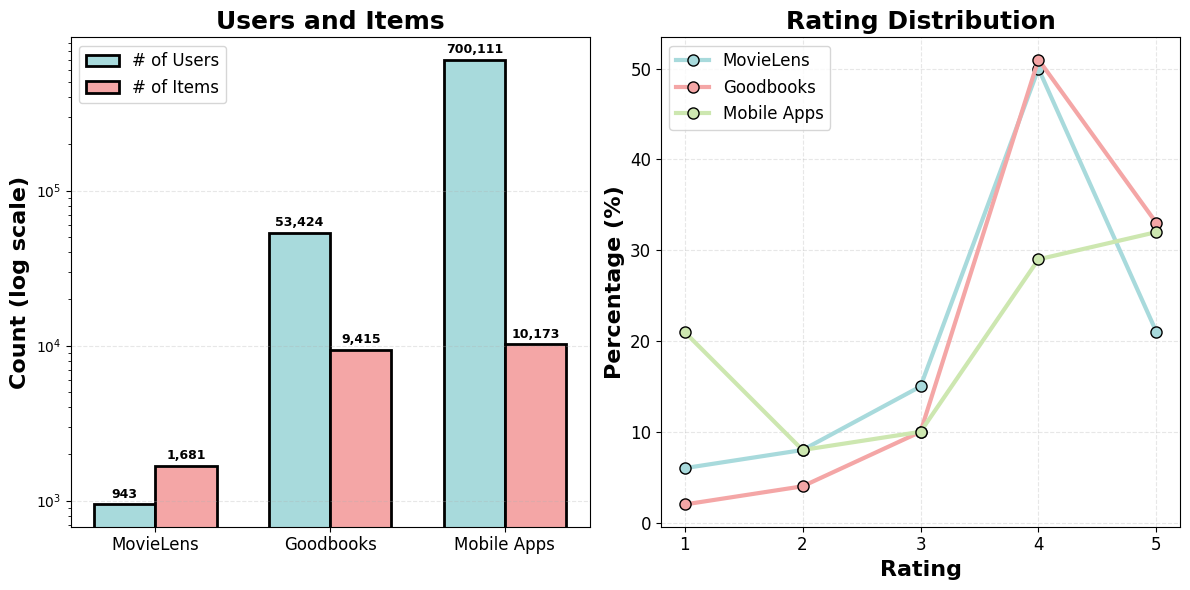

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# =========================
# DATA
# =========================

datasets = ["MovieLens", "Goodbooks", "Mobile Apps"]

users = [943, 53424, 700111]
items = [1681, 9415, 10173]

ratings = [1, 2, 3, 4, 5]

movielens = [6, 8, 15, 50, 21]
goodbooks = [2, 4, 10, 51, 33]
mobile_apps = [21, 8, 10, 29, 32]

# =========================
# COLORS
# =========================

colors = {
    "MovieLens": "#A8DADC",   # pastel blue
    "Goodbooks": "#F4A6A6",   # pastel pink
    "Mobile Apps": "#CDE7B0"  # pastel green
}

user_color = "#A8DADC"
item_color = "#F4A6A6"

# =========================
# FIGURE
# =========================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# =====================================================
# LEFT: USERS + ITEMS
# =====================================================

x = np.arange(len(datasets))
width = 0.35

bars1 = ax1.bar(
    x - width/2,
    users,
    width,
    label="# of Users",
    color=user_color,
    edgecolor="black",
    linewidth=2
)

bars2 = ax1.bar(
    x + width/2,
    items,
    width,
    label="# of Items",
    color=item_color,
    edgecolor="black",
    linewidth=2
)

# Log scale
ax1.set_yscale("log")

# Value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()

        ax1.text(
            bar.get_x() + bar.get_width()/2,
            height * 1.1,
            f"{int(height):,}",
            ha='center',
            fontsize=9,
            fontweight="bold"
        )

# Labels
ax1.set_ylabel("Count (log scale)",
               fontsize=16,
               fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(datasets, fontsize=12)

# Title
ax1.set_title("Users and Items",
              fontsize=18,
              fontweight="bold")

# Legend
ax1.legend(fontsize=12)

# Grid
ax1.grid(True,
         axis='y',
         linestyle='--',
         alpha=0.3)

# =====================================================
# RIGHT: RATING DISTRIBUTION
# =====================================================

ax2.plot(ratings, movielens,
         marker='o',
         linewidth=3,
         markersize=8,
         color=colors["MovieLens"],
         markerfacecolor=colors["MovieLens"],
         markeredgecolor="black",
         label='MovieLens')

ax2.plot(ratings, goodbooks,
         marker='o',
         linewidth=3,
         markersize=8,
         color=colors["Goodbooks"],
         markerfacecolor=colors["Goodbooks"],
         markeredgecolor="black",
         label='Goodbooks')

ax2.plot(ratings, mobile_apps,
         marker='o',
         linewidth=3,
         markersize=8,
         color=colors["Mobile Apps"],
         markerfacecolor=colors["Mobile Apps"],
         markeredgecolor="black",
         label='Mobile Apps')

# Labels
ax2.set_xlabel("Rating",
               fontsize=16,
               fontweight="bold")

ax2.set_ylabel("Percentage (%)",
               fontsize=16,
               fontweight="bold")

# Title
ax2.set_title("Rating Distribution",
              fontsize=18,
              fontweight="bold")

# Ticks
ax2.set_xticks(ratings)
ax2.tick_params(axis='both', labelsize=12)

# Grid
ax2.grid(True,
         linestyle='--',
         alpha=0.3)

# Legend
ax2.legend(fontsize=12)

# =====================================================
# FINAL LAYOUT
# =====================================================

plt.tight_layout()

# Save
plt.savefig("/home/moshtasa/Research/phd-svd-recsys/Book/current/0420/NMF_SVD_Comparisons/9/combined_dataset_figure.png", dpi=300)

plt.show()

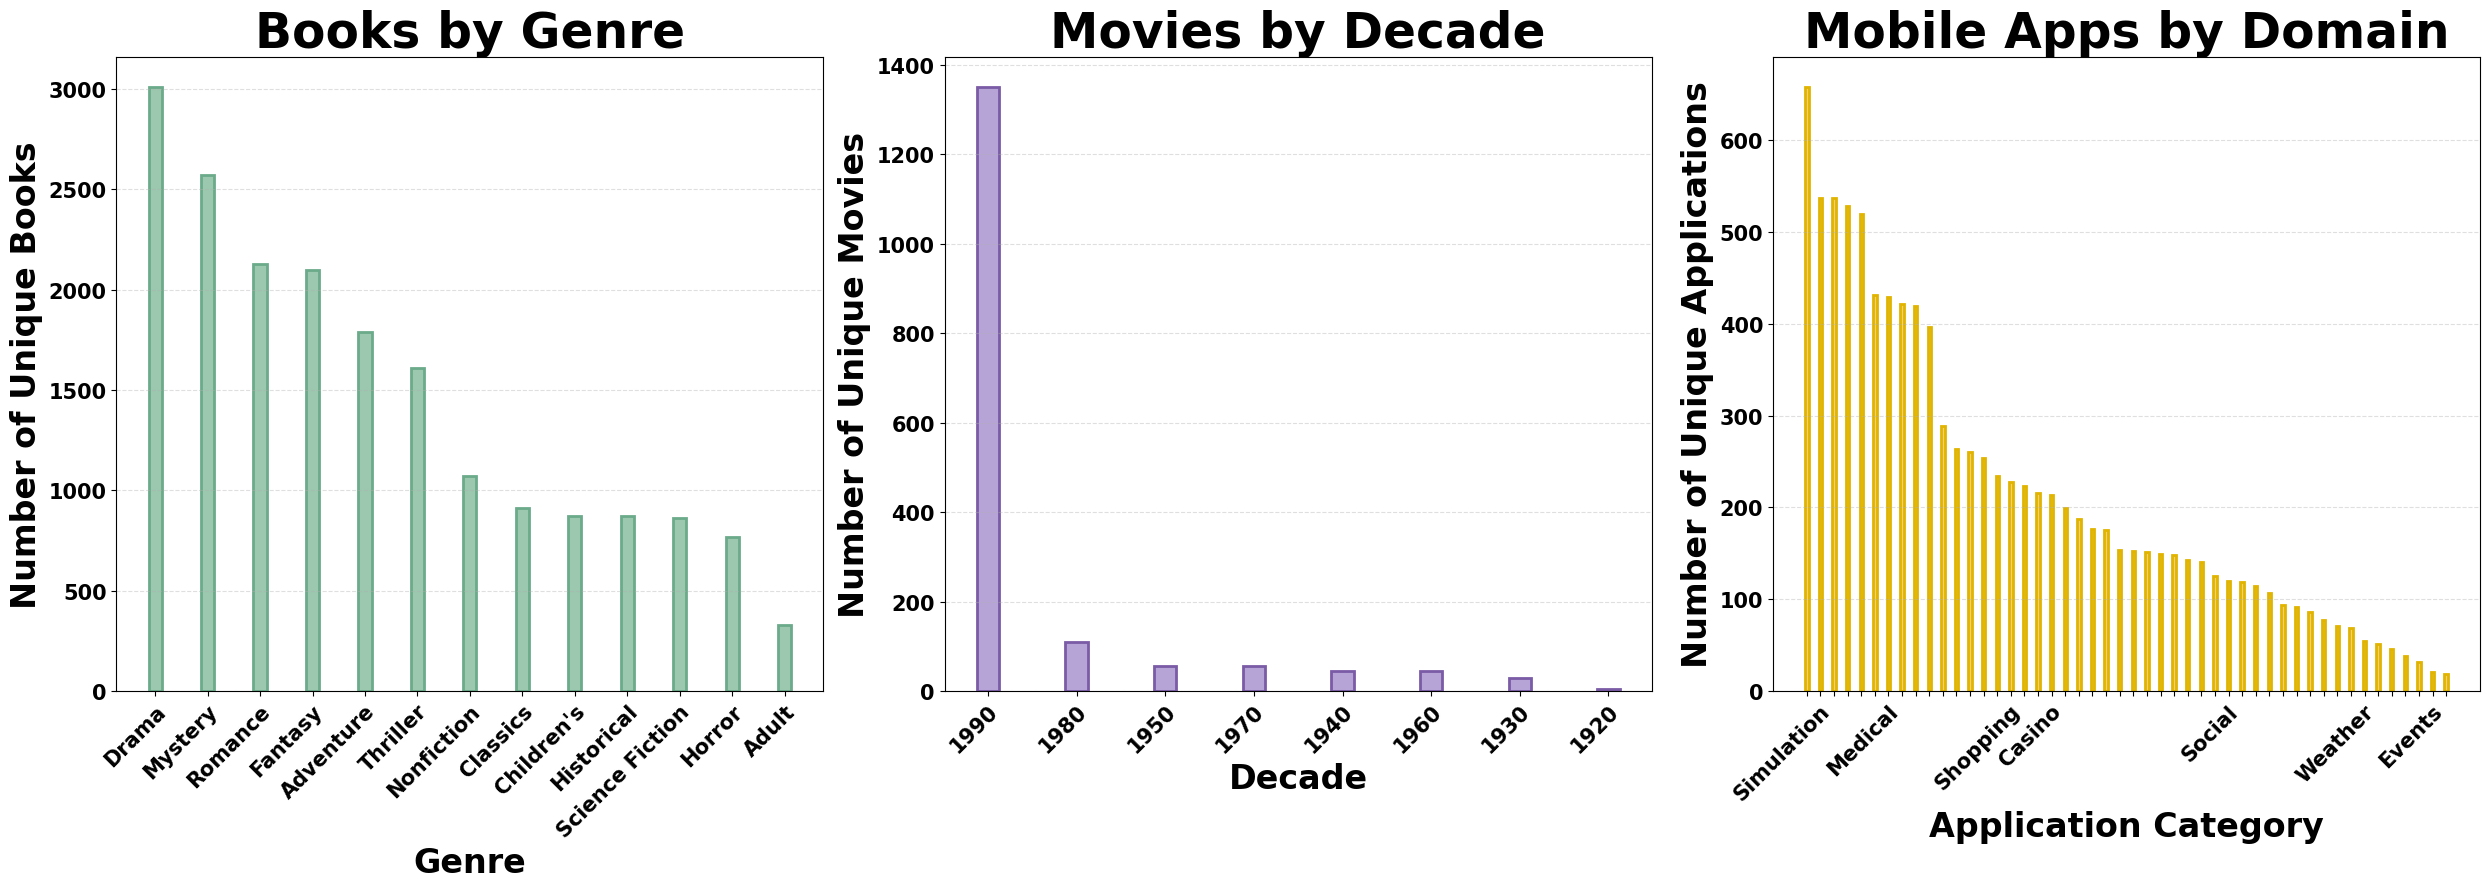

In [4]:
import matplotlib.pyplot as plt

# =========================================
# GLOBAL FONT SETTINGS
# =========================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# =========================================
# FONT SIZES
# =========================================

TITLE_F = 35
LABEL_F = 24
TICK_F = 15

# =========================================
# BAR WIDTH
# =========================================

BAR_WIDTH = 0.25

# =========================================
# DATA
# =========================================

# Books
book_genres = [
    "Drama", "Mystery", "Romance", "Fantasy",
    "Adventure", "Thriller", "Nonfiction",
    "Classics", "Children's", "Historical",
    "Science Fiction", "Horror", "Adult"
]

book_counts = [
    3010, 2570, 2130, 2100,
    1790, 1610, 1070,
    910, 870, 870,
    860, 770, 330
]

# Movies
movie_decades = [
    "1990", "1980", "1950", "1970",
    "1940", "1960", "1930", "1920"
]

movie_counts = [
    1350, 110, 55, 55,
    45, 45, 30, 5
]

# Mobile Apps
app_domains = [
    "Role Playing",
    "Puzzle",
    "Simulation",
    "Action",
    "Strategy",
    "Casual",
    "Education",
    "Medical",
    "Educational",
    "Adventure",
    "Sports",
    "Arcade",
    "Productivity",
    "Finance",
    "Dating",
    "Travel & Local",
    "Shopping",
    "Entertainment",
    "Tools",
    "Casino",
    "Card",
    "Libraries & Demo",
    "Music & Audio",
    "Board",
    "Business",
    "Food & Drink",
    "Word",
    "Health & Fitness",
    "Lifestyle",
    "Racing",
    "Communication",
    "Personalization",
    "Social",
    "Photography",
    "Books & Reference",
    "Video Players & Editors",
    "Maps & Navigation",
    "Music",
    "House & Home",
    "Parenting",
    "News & Magazines",
    "Art & Design",
    "Weather",
    "Auto & Vehicles",
    "Comics",
    "Trivia",
    "Beauty",
    "Events"
]

app_counts = [
    658,
    537,
    537,
    529,
    520,
    432,
    429,
    422,
    420,
    397,
    289,
    264,
    260,
    254,
    234,
    228,
    223,
    216,
    214,
    199,
    187,
    176,
    175,
    154,
    153,
    151,
    149,
    148,
    143,
    141,
    125,
    120,
    119,
    114,
    107,
    94,
    92,
    86,
    77,
    71,
    69,
    54,
    51,
    46,
    38,
    32,
    21,
    18
]

# =========================================
# TARGET LABELS
# =========================================

TARGET_CATEGORIES = [
    "Medical",
    "Weather",
    "Events",
    "Shopping",
    "Simulation",
    "Casino",
    "Social"
]

# =========================================
# FIGURE
# =========================================

fig, axes = plt.subplots(1, 3, figsize=(25, 9))

# =========================================
# 1. BOOKS
# =========================================

axes[0].bar(
    book_genres,
    book_counts,
    width=BAR_WIDTH,
    color="#9BC8AE",
    edgecolor="#6BAA8A",
    linewidth=2
)

axes[0].set_title(
    "Books by Genre",
    fontsize=TITLE_F,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Number of Unique Books",
    fontsize=LABEL_F,
    fontweight="bold"
)

axes[0].set_xlabel(
    "Genre",
    fontsize=LABEL_F,
    fontweight="bold"
)

axes[0].tick_params(
    axis='x',
    labelsize=TICK_F
)

axes[0].tick_params(
    axis='y',
    labelsize=TICK_F
)

plt.setp(
    axes[0].get_xticklabels(),
    rotation=45,
    ha='right',
    rotation_mode='anchor'
)

for label in axes[0].get_xticklabels():
    label.set_fontweight('bold')

for label in axes[0].get_yticklabels():
    label.set_fontweight('bold')

axes[0].grid(
    True,
    axis='y',
    linestyle='--',
    alpha=0.4
)

# =========================================
# 2. MOVIES
# =========================================

axes[1].bar(
    movie_decades,
    movie_counts,
    width=BAR_WIDTH,
    color="#B7A4D7",
    edgecolor="#7A5BA6",
    linewidth=2
)

axes[1].set_title(
    "Movies by Decade",
    fontsize=TITLE_F,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Number of Unique Movies",
    fontsize=LABEL_F,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Decade",
    fontsize=LABEL_F,
    fontweight="bold"
)

axes[1].tick_params(
    axis='x',
    labelsize=TICK_F
)

axes[1].tick_params(
    axis='y',
    labelsize=TICK_F
)

plt.setp(
    axes[1].get_xticklabels(),
    rotation=45,
    ha='right',
    rotation_mode='anchor'
)

for label in axes[1].get_xticklabels():
    label.set_fontweight('bold')

for label in axes[1].get_yticklabels():
    label.set_fontweight('bold')

axes[1].grid(
    True,
    axis='y',
    linestyle='--',
    alpha=0.4
)

# =========================================
# 3. MOBILE APPS
# =========================================

axes[2].bar(
    app_domains,
    app_counts,
    width=BAR_WIDTH,
    color="#F4D06F",
    edgecolor="#E0B400",
    linewidth=2
)

axes[2].set_title(
    "Mobile Apps by Domain",
    fontsize=TITLE_F,
    fontweight="bold"
)

axes[2].set_ylabel(
    "Number of Unique Applications",
    fontsize=LABEL_F,
    fontweight="bold"
)

axes[2].set_xlabel(
    "Application Category",
    fontsize=LABEL_F,
    fontweight="bold"
)

axes[2].tick_params(
    axis='y',
    labelsize=TICK_F
)

# ONLY SHOW TARGET LABELS
axes[2].set_xticks(range(len(app_domains)))

axes[2].set_xticklabels(
    [
        label if label in TARGET_CATEGORIES else ""
        for label in app_domains
    ],
    rotation=45,
    ha='right',
    fontsize=TICK_F,
    fontweight='bold'
)

for label in axes[2].get_yticklabels():
    label.set_fontweight('bold')

axes[2].grid(
    True,
    axis='y',
    linestyle='--',
    alpha=0.4
)

# =========================================
# FINAL LAYOUT
# =========================================

plt.tight_layout()

plt.savefig(
    "/home/moshtasa/Research/phd-recsys/Book/current/Data/domain_analysis/figures/combined_3plots_A4.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

###Mobile

In [ ]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
from pathlib import Path

# ── Paths ──
BASE_NMF = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405/0405_NMF/result"
BASE_SVD = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405/0405_SVD/result"

NMF_FIG_DIR = os.path.join(BASE_NMF, "0405_NMF_details_figures")
SVD_FIG_DIR = os.path.join(BASE_SVD, "0405_SVD_details_figures")

NMF_BAR_FIG_DIR = os.path.join(BASE_NMF, "0405_NMF_bar_figures")
SVD_BAR_FIG_DIR = os.path.join(BASE_SVD, "0405_SVD_bar_figures")

# ── Output directory (organized by genre) ──
OUTPUT_BASE = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405/NMF_SVD_Comparisons"
os.makedirs(OUTPUT_BASE, exist_ok=True)

# =========================
# LOAD DATA
# =========================

def load_data(BASE):
    BI_DIR = os.path.join(BASE, "bi")
    MU_DIR = os.path.join(BASE, "mio")
    BU_DIR = os.path.join(BASE, "bu")

    BI_PATTERN = re.compile(r"^f_(.+?)_(\d+)u_pos5_neg1_books_bi_per_genre\.csv$")

    merged_data = {}
    bu_data = {}

    for fname in os.listdir(BI_DIR):
        m = BI_PATTERN.match(fname)
        if not m:
            continue

        genre_key = m.group(1)
        n = int(m.group(2))

        bi_path = os.path.join(BI_DIR, fname)
        mu_path = os.path.join(MU_DIR, fname.replace("_bi_", "_mu_"))
        bu_path = os.path.join(BU_DIR, fname.replace("_bi_", "_bu_").replace("_per_genre.csv", "_per_genre_biased.csv"))

        if not (os.path.exists(mu_path) and os.path.exists(bu_path)):
            continue

        df_bi = pd.read_csv(bi_path)
        df_mu = pd.read_csv(mu_path)
        df_bu = pd.read_csv(bu_path)

        # Normalize and exclude unknown genre
        for df in [df_bi, df_mu, df_bu]:
            if "genre" in df.columns:
                df["genre"] = df["genre"].astype(str).str.strip()
                df_filtered = df[df["genre"].str.lower() != "unknown"].copy()
                # Update references (for bu_data)
                if df is df_bu:
                    df_bu = df_filtered
                elif df is df_bi:
                    df_bi = df_filtered
                else:
                    df_mu = df_filtered

        # Keep raw BU data separately
        bu_data[(genre_key, n)] = df_bu.copy()

        # For merged plots, use only non_biasing BU rows
        if "user_type" in df_bu.columns:
            df_bu_merge = df_bu[df_bu["user_type"] == "non_biasing"].copy()
            if df_bu_merge.empty:
                df_bu_merge = df_bu.copy()
        else:
            df_bu_merge = df_bu.copy()

        merge_cols = ["genre"]
        if "is_target" in df_bi.columns:
            merge_cols.append("is_target")

        df = pd.merge(df_mu, df_bi, on=merge_cols, how="outer")
        df = pd.merge(df, df_bu_merge, on=merge_cols, how="outer")

        merged_data[(genre_key, n)] = df

    genre_groups = defaultdict(dict)
    for (genre_key, n), df in merged_data.items():
        genre_groups[genre_key][n] = df

    bu_groups = defaultdict(dict)
    for (genre_key, n), df in bu_data.items():
        bu_groups[genre_key][n] = df

    return genre_groups, bu_groups

nmf_groups, nmf_bu_groups = load_data(BASE_NMF)
svd_groups, svd_bu_groups = load_data(BASE_SVD)

# =========================
# STYLE
# =========================

plt.style.use("seaborn-v0_8-pastel")

TARGET_COLOR = "#5B3A29"
TARGET_LINEWIDTH = 3.5
NON_TARGET_LINEWIDTH = 1.5

PASTEL_COLORS = [
    "#AEC6CF","#FFD1DC","#B5EAD7","#FFDAC1","#C3B1E1","#F3E5AB",
    "#FFB7B2","#B0E0E6","#D5AAFF","#FFFACD","#E0BBE4","#957DAD",
    "#D4E157","#80CBC4","#F48FB1",
]

# Colors for BU bias comparison
TARGET_BIAS_COLOR = "#8B0000"
TARGET_NONBIAS_COLOR = "#5B3A29"
NONTARGET_BIAS_COLOR = "#1F77B4"
NONTARGET_NONBIAS_COLOR = "#7FB3D5"

# =========================
# HELPER FUNCTIONS
# =========================

def get_single_value(row, col):
    """Extract single value from dataframe row."""
    if row.empty or col not in row.columns:
        return None
    return row[col].values[0]


def generate_subplot(ax, series, all_genres, target_genre_name, sorted_ns, model_name, genre_key):
    """
    Generate a single subplot for NMF or SVD.
    Returns legend handles dict for later use.
    
    CUSTOMIZATION: Adjust font sizes, colors, and styling here.
    """
    
    non_target_genres = [g for g in all_genres if g != target_genre_name]

    color_map = {}
    for i, g in enumerate(non_target_genres):
        color_map[g] = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    color_map[target_genre_name] = TARGET_COLOR

    positions = list(range(len(sorted_ns)))
    n_to_pos = {n: p for n, p in zip(sorted_ns, positions)}

    legend_handles = {}

    # Plot non-target genres
    for g in non_target_genres:
        pts = series.get(g, [])
        if pts:
            xs = [n_to_pos[x] for x, _ in pts]
            ys = [y for _, y in pts]
            line, = ax.plot(xs, ys, marker="o",
                            color=color_map[g],
                            linewidth=NON_TARGET_LINEWIDTH,
                            markersize=9,
                            alpha=0.8,
                            label=g)
            legend_handles[g] = line

    # Plot target genre
    pts = series.get(target_genre_name, [])
    if pts:
        xs = [n_to_pos[x] for x, _ in pts]
        ys = [y for _, y in pts]
        line, = ax.plot(xs, ys, marker="o",
                        color=TARGET_COLOR,
                        linewidth=TARGET_LINEWIDTH,
                        markersize=7,
                        label=f"{target_genre_name} (target)",
                        zorder=10)
        legend_handles[target_genre_name] = line

    pretty = genre_key.replace("_", " ")

    ax.tick_params(axis='y', labelsize=18)
    ax.tick_params(axis='x', labelsize=20)

    ax.set_title(f"{model_name} - {pretty}", fontsize=26, fontweight='bold')
    ax.set_xlabel("Number of Fictitious Users (n)", fontsize=22, fontweight="bold")

    ax.set_xticks(positions)
    ax.set_xticklabels([str(n) for n in sorted_ns], rotation=45)

    ax.grid(True, alpha=0.3)

    return legend_handles


def build_series(n_dict, sorted_ns, compute_value):
    """
    Build series data for all genres across different n values.
    
    CUSTOMIZATION: Modify compute_value lambda to change metric calculation.
    """
    all_genres = set()
    for n in sorted_ns:
        all_genres.update(n_dict[n]["genre"].tolist())
    all_genres = sorted(all_genres)

    series = {}
    for g in all_genres:
        pts = []
        for n in sorted_ns:
            df = n_dict[n]
            row = df[df["genre"] == g]
            if not row.empty:
                val = compute_value(row)
                if val is not None:
                    pts.append((n, val))
        series[g] = pts

    return series, all_genres


def plot_merged_figures(genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name, 
                       compute_value, ylabel, metric_name, suffix):
    """
    Create a merged NMF-SVD comparison figure for a specific metric.
    
    CUSTOMIZATION: Modify ylabel, metric_name, and suffix for different metrics.
    """
    
    nmf_series, all_genres = build_series(nmf_dict, sorted_ns, compute_value)
    svd_series, _ = build_series(svd_dict, sorted_ns, compute_value)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 6),
        sharey=True,
        constrained_layout=True
    )

    # Generate NMF subplot
    nmf_legend_handles = generate_subplot(
        axes[0], nmf_series, all_genres, target_genre_name, sorted_ns, "NMF", genre_key
    )

    # Generate SVD subplot
    svd_legend_handles = generate_subplot(
        axes[1], svd_series, all_genres, target_genre_name, sorted_ns, "SVD", genre_key
    )

    # Use NMF legend (both should be the same)
    legend_handles = nmf_legend_handles

    # Set y-label on left subplot only
    axes[0].set_ylabel(ylabel, fontweight="bold", fontsize=26)

    # Add legend at top
    fig.legend(
        list(legend_handles.values()),
        list(legend_handles.keys()),
        loc="upper center",
        bbox_to_anchor=(0.5, 1.22),
        fontsize=20,
        ncol=min(len(legend_handles), 7),
        handlelength=1.2,
        handletextpad=0.6,
        columnspacing=0.8
    )

    # Save to genre-specific folder
    genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
    os.makedirs(genre_output_dir, exist_ok=True)

    merged_path = os.path.join(genre_output_dir, f"{genre_key}_{suffix}.png")
    fig.savefig(merged_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f"  ✓ {suffix}: {merged_path}")


def plot_bu_bias_comparison_merged(genre_key, sorted_ns, nmf_bu_dict, svd_bu_dict):
    """
    Create merged NMF-SVD comparison for BU bias analysis.
    
    CUSTOMIZATION: Modify colors, markers, and series labels here.
    """
    
    positions = list(range(len(sorted_ns)))
    n_to_pos = {n: p for n, p in zip(sorted_ns, positions)}

    # ────── NMF side ──────
    nmf_target_bias_pts = []
    nmf_target_nonbias_pts = []
    nmf_non_target_bias_pts = []
    nmf_non_target_nonbias_pts = []

    for n in sorted_ns:
        df = nmf_bu_dict[n].copy()

        if "genre" in df.columns:
            df["genre"] = df["genre"].astype(str).str.strip()
            df = df[df["genre"].str.lower() != "unknown"]

        if "user_type" in df.columns:
            df["user_type"] = df["user_type"].astype(str).str.strip()

        if "is_target" in df.columns:
            df["is_target"] = df["is_target"].astype(str).str.strip()

        # Target + biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "biasing")]
        if not row.empty:
            nmf_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Target + non_biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            nmf_target_nonbias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "biasing")]
        if not row.empty:
            nmf_non_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + non_biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            nmf_non_target_nonbias_pts.append((n, row["avg_bu"].mean()))

    # ────── SVD side ──────
    svd_target_bias_pts = []
    svd_target_nonbias_pts = []
    svd_non_target_bias_pts = []
    svd_non_target_nonbias_pts = []

    for n in sorted_ns:
        df = svd_bu_dict[n].copy()

        if "genre" in df.columns:
            df["genre"] = df["genre"].astype(str).str.strip()
            df = df[df["genre"].str.lower() != "unknown"]

        if "user_type" in df.columns:
            df["user_type"] = df["user_type"].astype(str).str.strip()

        if "is_target" in df.columns:
            df["is_target"] = df["is_target"].astype(str).str.strip()

        # Target + biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "biasing")]
        if not row.empty:
            svd_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Target + non_biasing
        row = df[(df["is_target"] == "target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            svd_target_nonbias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "biasing")]
        if not row.empty:
            svd_non_target_bias_pts.append((n, row["avg_bu"].mean()))

        # Non-target + non_biasing
        row = df[(df["is_target"] == "non_target") & (df["user_type"] == "non_biasing")]
        if not row.empty:
            svd_non_target_nonbias_pts.append((n, row["avg_bu"].mean()))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True, constrained_layout=True)

    # NMF subplot
    for label, pts, color, linewidth, marker in [
        ("Target - biasing", nmf_target_bias_pts, TARGET_BIAS_COLOR, 3.5, "o"),
        ("Target - non_biasing", nmf_target_nonbias_pts, TARGET_NONBIAS_COLOR, 3.5, "s"),
        ("Non-target - biasing", nmf_non_target_bias_pts, NONTARGET_BIAS_COLOR, 2.5, "^"),
        ("Non-target - non_biasing", nmf_non_target_nonbias_pts, NONTARGET_NONBIAS_COLOR, 2.5, "D"),
    ]:
        if pts:
            xs = [n_to_pos[x] for x, _ in pts]
            ys = [y for _, y in pts]
            axes[0].plot(xs, ys, marker=marker, color=color, linewidth=linewidth, 
                        markersize=8, label=label)

    # SVD subplot
    for label, pts, color, linewidth, marker in [
        ("Target - biasing", svd_target_bias_pts, TARGET_BIAS_COLOR, 3.5, "o"),
        ("Target - non_biasing", svd_target_nonbias_pts, TARGET_NONBIAS_COLOR, 3.5, "s"),
        ("Non-target - biasing", svd_non_target_bias_pts, NONTARGET_BIAS_COLOR, 2.5, "^"),
        ("Non-target - non_biasing", svd_non_target_nonbias_pts, NONTARGET_NONBIAS_COLOR, 2.5, "D"),
    ]:
        if pts:
            xs = [n_to_pos[x] for x, _ in pts]
            ys = [y for _, y in pts]
            axes[1].plot(xs, ys, marker=marker, color=color, linewidth=linewidth,
                        markersize=8, label=label)

    pretty = genre_key.replace("_", " ")

    for ax, model_name in zip(axes, ["NMF", "SVD"]):
        ax.set_title(f"{model_name} - {pretty} (bᵤ biased vs unbiased)", fontsize=26, fontweight='bold')
        ax.set_xlabel("Number of Fictitious Users (n)", fontsize=22, fontweight="bold")
        ax.set_xticks(positions)
        ax.set_xticklabels([str(n) for n in sorted_ns], rotation=45)
        ax.tick_params(axis="y", labelsize=18)
        ax.tick_params(axis="x", labelsize=20)
        ax.grid(True, alpha=0.3)

    axes[0].set_ylabel(r"$b_u$", fontweight="bold", fontsize=26)

    fig.legend(
        [line for line in axes[0].get_lines()],
        [line.get_label() for line in axes[0].get_lines()],
        loc="upper center",
        bbox_to_anchor=(0.5, 1.22),
        fontsize=20,
        ncol=2,
        handlelength=1.2,
        handletextpad=0.6,
        columnspacing=0.8
    )

    genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
    os.makedirs(genre_output_dir, exist_ok=True)

    merged_path = os.path.join(genre_output_dir, f"{genre_key}_bu_biased_vs_unbiased_target_vs_nontarget.png")
    fig.savefig(merged_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(f"  ✓ bu_biased_vs_unbiased: {merged_path}")


def parse_txt(file_path):
    """
    Parse txt file containing k values and metrics.
    Format: k = X, followed by metric_name: value pairs
    """
    data = {}
    current_k = None

    with open(file_path, "r") as f:
        for line in f:
            line = line.strip()

            if line.startswith("k ="):
                current_k = int(line.split("=")[1].strip())
                data[current_k] = {}

            elif ":" in line and current_k is not None:
                match = re.match(r"(.*?)\:\s*([0-9.]+)", line)
                if match:
                    label = match.group(1).strip()
                    value = float(match.group(2))
                    data[current_k][label] = value

    return data


def generate_colors(n_list):
    """
    Generate distinct colors for each n_type.
    CUSTOMIZATION: Adjust colormap here if needed.
    """
    cmap = plt.cm.get_cmap('tab20', len(n_list))
    return {n: cmap(i) for i, n in enumerate(n_list)}


def extract_genre(folder_name):
    """
    Extract genre name from bar figure folder name.
    Example: 'k_adult' -> 'adult'
    """
    parts = folder_name.lower().split("_")
    return parts[1] if len(parts) > 1 else None


def plot_bar_chart_merged(genre_key):
    """
    Create merged NMF-SVD bar chart comparison for k-value metrics.
    Uses the same directory structure as the original bar figure code.
    
    CUSTOMIZATION: Modify colors, bar widths, and legend here.
    """
    
    # Use Path objects like the original code
    BASE_PATHS = {
        "NMF": Path(NMF_BAR_FIG_DIR),
        "SVD": Path(SVD_BAR_FIG_DIR),
    }
    
    # Extract genre folders (e.g., "k_adult", "k_classics")
    def extract_genre_from_folder(folder_name):
        parts = folder_name.lower().split("_")
        return parts[1] if len(parts) > 1 else None
    
    nmf_map = {
        extract_genre_from_folder(f): f
        for f in os.listdir(BASE_PATHS["NMF"])
        if (BASE_PATHS["NMF"] / f).is_dir()
    }
    
    svd_map = {
        extract_genre_from_folder(f): f
        for f in os.listdir(BASE_PATHS["SVD"])
        if (BASE_PATHS["SVD"] / f).is_dir()
    }
    
    # Check if this genre exists in both NMF and SVD
    if genre_key not in nmf_map or genre_key not in svd_map:
        return False
    
    nmf_folder = nmf_map[genre_key]
    svd_folder = svd_map[genre_key]
    
    paths = {
        "NMF": BASE_PATHS["NMF"] / nmf_folder,
        "SVD": BASE_PATHS["SVD"] / svd_folder,
    }
    
    parsed_data = {}
    
    for method, folder_path in paths.items():
        txt_files = [f for f in os.listdir(folder_path) if f.endswith(".txt")]
        if not txt_files:
            return False
        
        txt_path = folder_path / txt_files[0]
        parsed_data[method] = parse_txt(str(txt_path))
    
    if len(parsed_data) < 2:
        return False
    
    # Filter for specific k values
    ks = [k for k in sorted(parsed_data["NMF"].keys()) if k in [15, 25, 35]]
    if not ks:
        return False
    
    # Collect all n_types
    n_types = sorted(set(
        n
        for method in parsed_data
        for k in ks
        for n in parsed_data[method][k].keys()
    ), key=lambda x: (x != "original", int(x.replace("u", "")) if x != "original" else -1))
    
    color_map = generate_colors(n_types)
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)
    
    legend_handles = []
    legend_labels = []
    
    for ax, method in zip(axes, ["NMF", "SVD"]):
        data = parsed_data[method]
        
        x = np.arange(len(ks)) * 1.3
        width = 1.1 / len(n_types)
        
        for i, n in enumerate(n_types):
            vals = [data[k].get(n, 0) for k in ks]
            
            bars = ax.bar(
                x + (i - len(n_types)/2) * width + width/2,
                vals,
                width=width,
                color=color_map[n],
                edgecolor="black",
                linewidth=1.5,
                label=n
            )
            
            # Collect legend only once (from NMF)
            if method == "NMF":
                legend_handles.append(bars[0])
                legend_labels.append(n)
        
        ax.spines["top"].set_visible(True)
        ax.spines["right"].set_visible(True)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
        
        genre_display = genre_key.replace('_', ' ').capitalize()
        ax.set_title(f"{method} - {genre_display}", fontsize=28, fontweight="bold", pad=10)
        
        ax.set_xticks(x)
        ax.set_xticklabels(ks, fontsize=24)
        ax.tick_params(axis='y', labelsize=24)
        
        ax.set_ylim(0, 40)
        ax.set_xlabel("k (recommendation size)", fontsize=26, fontweight="bold", labelpad=10)
    
    axes[0].set_ylabel("Avg count per user", fontsize=26, fontweight="bold", labelpad=10)
    
    # Add legend at top
    fig.legend(
        legend_handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.35, 1.1),
        fontsize=26,
        ncol=min(len(legend_labels), 8),
        handlelength=1.3,
        handletextpad=0.4,
        columnspacing=0.7
    )
    
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    
    # Save to genre-specific folder
    genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
    os.makedirs(genre_output_dir, exist_ok=True)
    
    merged_path = os.path.join(genre_output_dir, f"{genre_key}_k_value_comparison.png")
    fig.savefig(merged_path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    
    print(f"  ✓ k_value_comparison: {merged_path}")
    return True


# =========================
# MAIN LOOP
# =========================

for genre_key in sorted(nmf_groups.keys()):

    if genre_key not in svd_groups:
        continue

    nmf_dict = nmf_groups[genre_key]
    svd_dict = svd_groups[genre_key]

    sorted_ns = sorted(set(nmf_dict.keys()) & set(svd_dict.keys()))
    if not sorted_ns:
        continue

    sample_df = nmf_dict[sorted_ns[0]]
    target_rows = sample_df[sample_df["is_target"] == "target"]
    if target_rows.empty:
        continue

    target_genre_name = target_rows["genre"].iloc[0]

    print(f"\n📊 Processing genre: {genre_key}")

    # 1. μ + bi
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: (
            get_single_value(r, "global_mean_mu") + get_single_value(r, "avg_bi")
            if get_single_value(r, "global_mean_mu") is not None and get_single_value(r, "avg_bi") is not None
            else None
        ),
        r"$\mu + b_i$",
        "μ + bᵢ",
        "mu_plus_bi"
    )

    # 2. bi only
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: get_single_value(r, "avg_bi"),
        r"$b_i$",
        "bᵢ",
        "bi_only"
    )

    # 3. bu only
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: get_single_value(r, "avg_bu"),
        r"$b_u$",
        "bᵤ",
        "bu_only_non_biasing"
    )

    # 4. mu only
    plot_merged_figures(
        genre_key, sorted_ns, nmf_dict, svd_dict, target_genre_name,
        lambda r: get_single_value(r, "global_mean_mu"),
        r"$\mu$",
        "μ",
        "mu_only"
    )

    # 5. BU bias comparison (target vs non-target, biasing vs non-biasing)
    if genre_key in nmf_bu_groups and genre_key in svd_bu_groups:
        plot_bu_bias_comparison_merged(
            genre_key, sorted_ns,
            nmf_bu_groups[genre_key],
            svd_bu_groups[genre_key]
        )

    # 6. K-value bar chart comparison
    if not plot_bar_chart_merged(genre_key):
        print(f"  ⚠ Bar chart data not found for {genre_key}")


print("\n" + "="*70)
print("✨ All merged comparisons completed!")
print("="*70)
print(f"\nOutput directory: {OUTPUT_BASE}")
print("\nOrganization by genre:")
for genre_key in sorted(nmf_groups.keys()):
    if genre_key in svd_groups:
        genre_output_dir = os.path.join(OUTPUT_BASE, genre_key)
        if os.path.exists(genre_output_dir):
            print(f"  ├── {genre_key}/")





✨ All merged comparisons completed!

Output directory: /home/moshtasa/Research/phd-svd-recsys/Mobile/0405/NMF_SVD_Comparisons

Organization by genre:
Columns in df_bu:


NameError: name 'df_bu' is not defined

In [5]:
# SIMPLE SANITY CHECK

print("nmf_bu_groups keys:")
print(nmf_bu_groups.keys())

# take first genre
genre_key = list(nmf_bu_groups.keys())[0]

print("\nSelected genre:")
print(genre_key)

# take first n
n = list(nmf_bu_groups[genre_key].keys())[0]

print("\nSelected n:")
print(n)

# dataframe
df = nmf_bu_groups[genre_key][n]

print("\nColumns:")
print(df.columns.tolist())

print("\nHead:")
print(df.head())

nmf_bu_groups keys:
dict_keys([])


IndexError: list index out of range

###9X9 mu

✅ Loading: f_Shopping_2000u_pos5_neg1_allapps_mu_per_category.csv
Columns:
['category', 'avg_rating', 'std_rating', 'n_ratings', 'global_mean_mu', 'is_target']
Shape: (48, 6)
                  category  avg_rating  std_rating  n_ratings  global_mean_mu  \
0                 Shopping    3.962244    1.478832    1022137        2.155125   
1            Communication    2.314202    1.553645     673351        2.155125   
2         Health & Fitness    2.288400    1.612007     678312        2.155125   
3                   Social    2.280557    1.575820     594333        2.155125   
4  Video Players & Editors    2.278761    1.571226     466747        2.155125   

    is_target  
0      target  
1  non_target  
2  non_target  
3  non_target  
4  non_target  
✅ Loading: f_Shopping_7000u_pos5_neg1_allapps_mu_per_category.csv
Columns:
['category', 'avg_rating', 'std_rating', 'n_ratings', 'global_mean_mu', 'is_target']
Shape: (48, 6)
                  category  avg_rating  std_rating  n_ratings  glob

KeyError: 'genre'

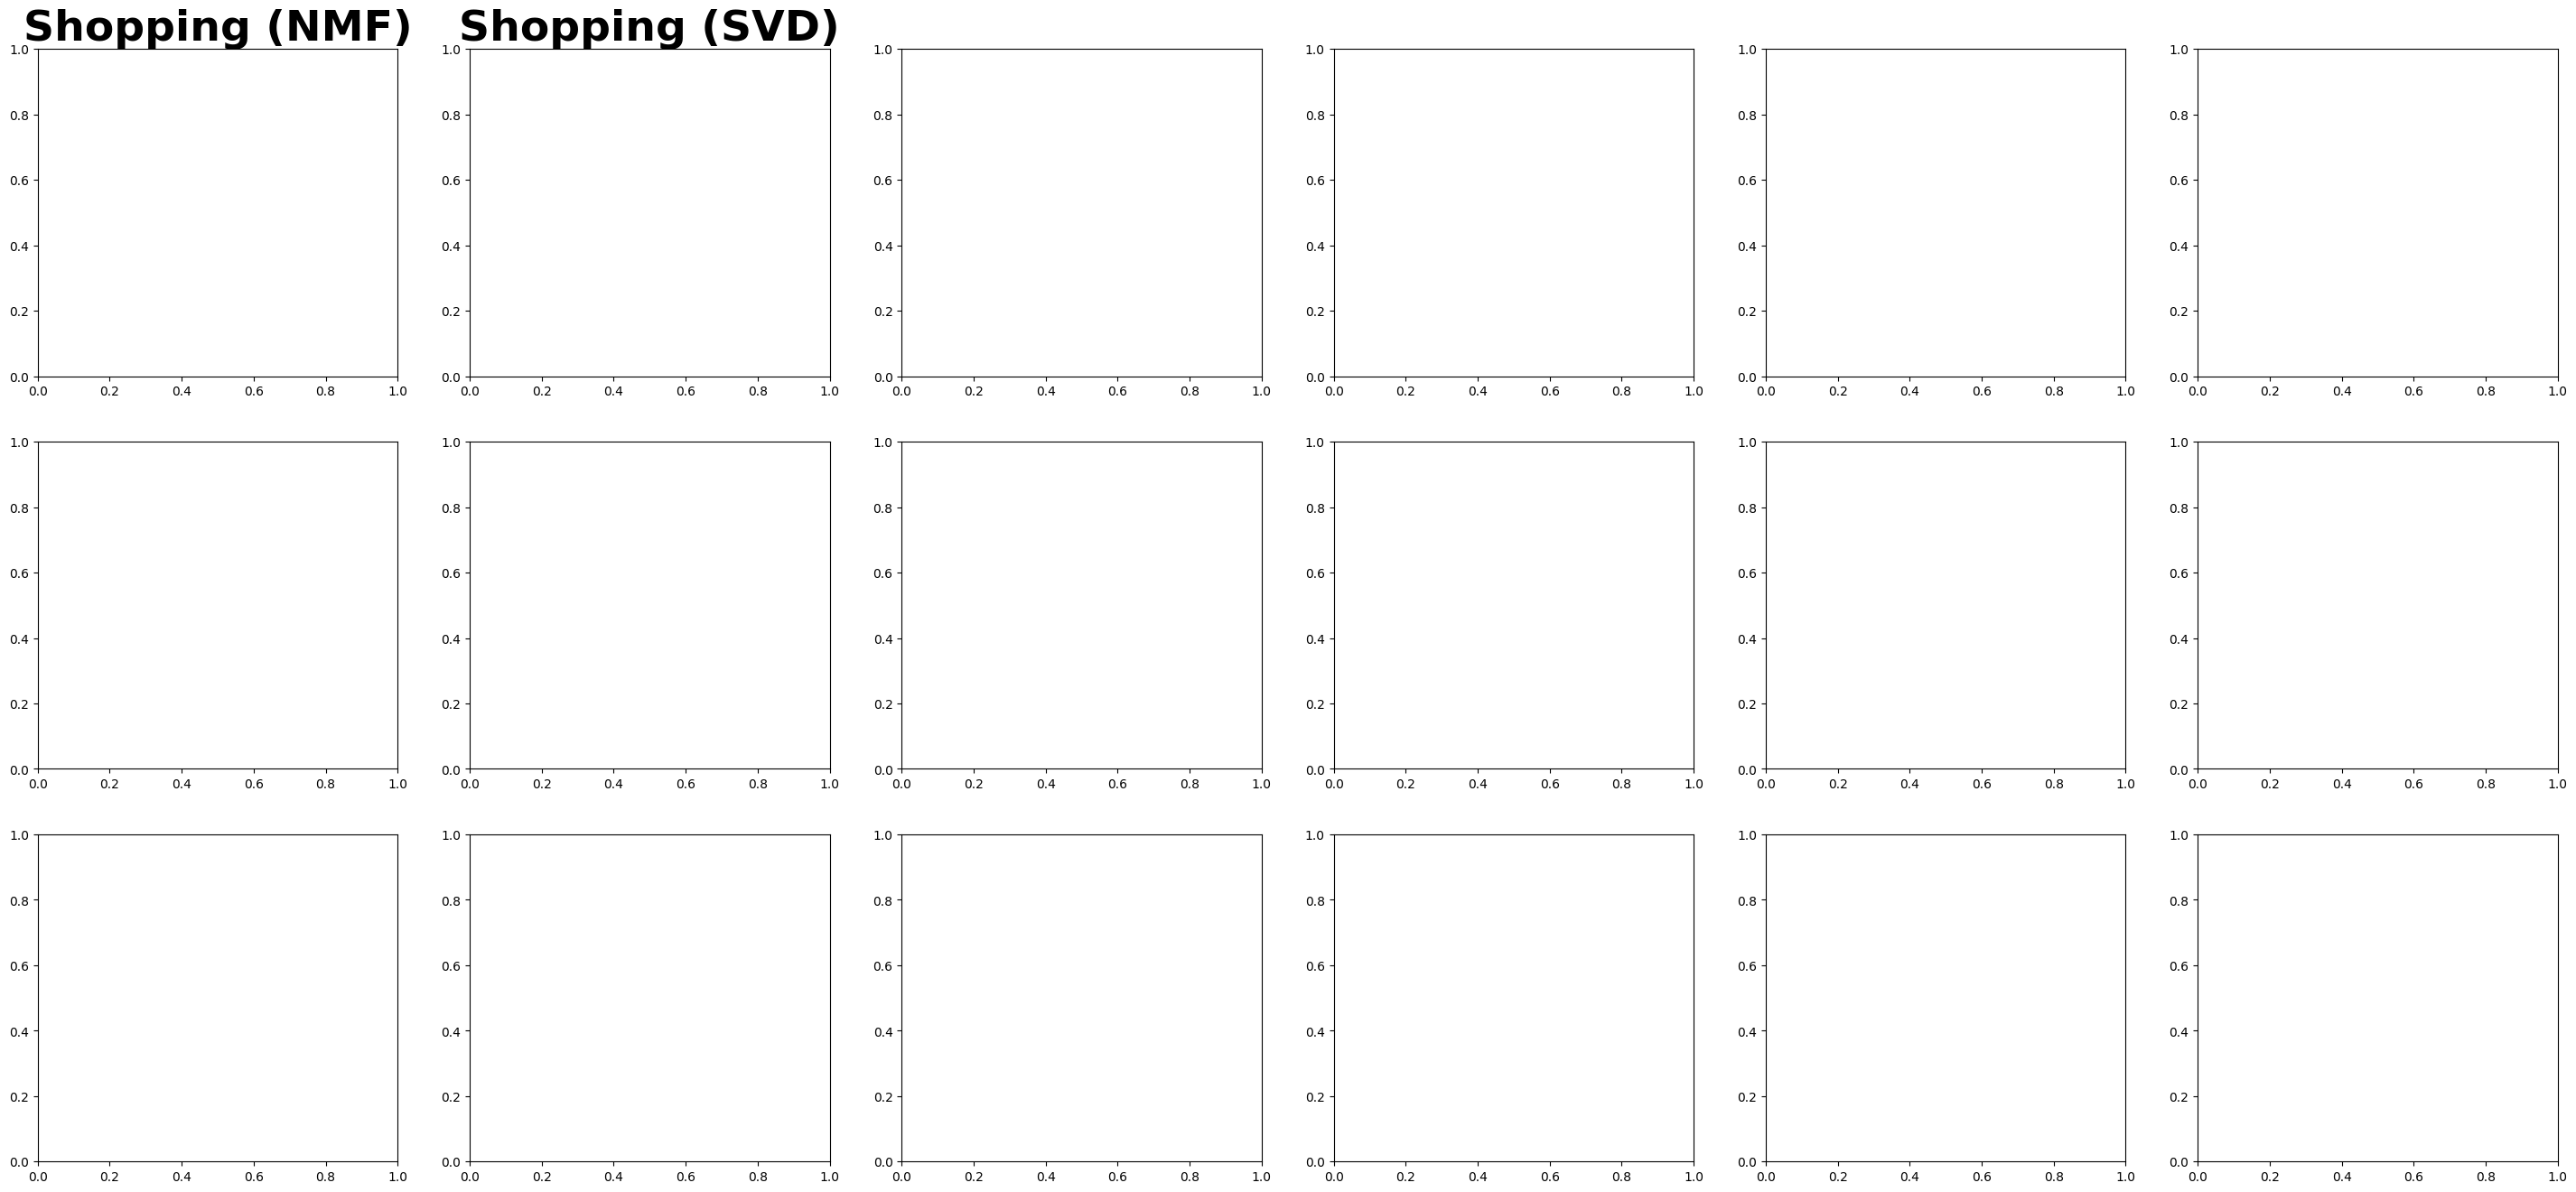

In [8]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# ── Paths ──
BASE_NMF = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405/0405_NMF/result"
BASE_SVD = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405/0405_SVD/result"

OUTPUT_BASE = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405//NMF_SVD_Comparisons/9"
os.makedirs(OUTPUT_BASE, exist_ok=True)

# =========================
# LOAD DATA
# =========================

def load_data(BASE):

    MU_DIR = os.path.join(BASE, "mio")

    MU_PATTERN = re.compile(
        r"^f_(.+?)_(\d+)u_pos5_neg1_allapps_mu_per_category\.csv$"
    )

    merged_data = {}

    for fname in os.listdir(MU_DIR):

        m = MU_PATTERN.match(fname)

        if not m:
            continue

        genre_key = m.group(1)
        n = int(m.group(2))

        mu_path = os.path.join(MU_DIR, fname)

        print(f"✅ Loading: {fname}")

        df_mu = pd.read_csv(mu_path)

        # clean genre
        if "genre" in df_mu.columns:

            df_mu["genre"] = (
                df_mu["genre"]
                .astype(str)
                .str.strip()
            )

            df_mu.drop(
                df_mu[df_mu["genre"].str.lower() == "unknown"].index,
                inplace=True
            )

        print("Columns:")
        print(df_mu.columns.tolist())

        print("Shape:", df_mu.shape)

        print(df_mu.head())

        merged_data[(genre_key, n)] = df_mu

    genre_groups = defaultdict(dict)

    for (genre_key, n), df in merged_data.items():
        genre_groups[genre_key][n] = df

    return genre_groups


nmf_groups = load_data(BASE_NMF)
svd_groups = load_data(BASE_SVD)

# =========================
# STYLE
# =========================

TITLE_F = 34
LABEL_F = 30
TICK_F = 30
SUPTITLE_F = 50

# =========================
# HELPERS
# =========================

def get_val(row, col):

    if row.empty:
        return None

    if col not in row.columns:
        return None

    val = row[col].values[0]

    if pd.isna(val):
        return None

    return val


def build_series(n_dict, sorted_ns, compute):

    genres = set()

    for n in sorted_ns:
        genres.update(n_dict[n]["genre"].tolist())

    genres = sorted(genres)

    series = {}

    for g in genres:

        pts = []

        for n in sorted_ns:

            row = n_dict[n][n_dict[n]["genre"] == g]

            val = compute(row)

            if val is not None:
                pts.append((n, val))

        series[g] = pts

    return series, genres


# =========================
# FIXED STYLE (NO GRID + BORDER)
# =========================

def apply_axis_style(ax, y_label="", show_x_label=True):

    if y_label:
        ax.set_ylabel(
            y_label,
            fontsize=LABEL_F,
            fontweight="bold"
        )

    x_ticks = [0, 500, 2000]

    if show_x_label:

        ax.set_xticks(x_ticks)

        ax.set_xticklabels(
            [str(t) for t in x_ticks],
            fontsize=TICK_F
        )

        ax.tick_params(axis='x', rotation=45)

    else:
        ax.set_xticks([])

    ax.tick_params(axis='y', labelsize=TICK_F)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)


# =========================
# FIXED PLOT (GREEN + THICK)
# =========================

def plot_one_model_on_axis(ax, groups, genre_key, compute):

    if genre_key not in groups:
        ax.axis('off')
        return

    n_dict = groups[genre_key]

    sorted_ns = sorted(n_dict.keys())

    print(f"\n📊 {genre_key}")
    print("sorted_ns:", sorted_ns)

    series, all_genres = build_series(
        n_dict,
        sorted_ns,
        compute
    )

    print("genres:", all_genres)

    for g in all_genres:

        pts = series[g]

        print(f"\nGenre: {g}")
        print("points:", pts)

        if not pts:
            continue

        xs = [n for n, _ in pts]
        ys = [y for _, y in pts]

        print("xs:", xs)
        print("ys:", ys)

        ax.plot(
            xs,
            ys,
            marker="o",
            markersize=8,
            linewidth=6,
            color="green"
        )


# =========================
# COMPARISON FIGURE
# =========================

def plot_mu_comparison_grid(nmf_groups, svd_groups):

    compute_fn = lambda r: get_val(r, "global_mean_mu")

    ylabel = r"$\mu$"

    genres = sorted(nmf_groups.keys())

    print("\nGENRES:")
    print(genres)

    fig, axes = plt.subplots(3, 6, figsize=(36, 16))

    for i, genre_key in enumerate(genres):

        row = i // 3

        col_nmf = (i % 3) * 2
        col_svd = col_nmf + 1

        ax_nmf = axes[row, col_nmf]
        ax_svd = axes[row, col_svd]

        ax_nmf.set_title(
            f"{genre_key.replace('_', ' ')} (NMF)",
            fontsize=TITLE_F,
            fontweight="bold"
        )

        ax_svd.set_title(
            f"{genre_key.replace('_', ' ')} (SVD)",
            fontsize=TITLE_F,
            fontweight="bold"
        )

        plot_one_model_on_axis(
            ax_nmf,
            nmf_groups,
            genre_key,
            compute_fn
        )

        plot_one_model_on_axis(
            ax_svd,
            svd_groups,
            genre_key,
            compute_fn
        )

        is_first_col = (col_nmf == 0)

        apply_axis_style(
            ax_nmf,
            y_label=ylabel if is_first_col else ""
        )

        apply_axis_style(ax_svd)

    fig.suptitle(
        "NMF vs SVD - Global Mean μ Comparison",
        fontsize=SUPTITLE_F,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0.05, 1, 0.92])

    path = os.path.join(
        OUTPUT_BASE,
        "NMF_vs_SVD_mu_comparison_3x6.png"
    )

    fig.savefig(path, dpi=150)

    plt.close()

    print(f"\n✓ Saved Comparison: {path}")


# =========================
# RUN
# =========================

print("\nGenerating fixed comparison figure...")

plot_mu_comparison_grid(
    nmf_groups,
    svd_groups
)

print("\nDONE ✅")

In [10]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# ── Paths ──
BASE_NMF = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405/0405_NMF/result"
BASE_SVD = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405/0405_SVD/result"

OUTPUT_BASE = "/home/moshtasa/Research/phd-svd-recsys/Mobile/0405//NMF_SVD_Comparisons/9"
os.makedirs(OUTPUT_BASE, exist_ok=True)

# =========================
# LOAD DATA
# =========================

def load_data(BASE):

    MU_DIR = os.path.join(BASE, "mio")

    MU_PATTERN = re.compile(
        r"^f_(.+?)_(\d+)u_pos5_neg1_allapps_mu_per_category\.csv$"
    )

    grouped_data = {}

    for fname in os.listdir(MU_DIR):

        m = MU_PATTERN.match(fname)

        if not m:
            continue

        genre_key = m.group(1)
        n = int(m.group(2))

        mu_path = os.path.join(MU_DIR, fname)

        print(f"✅ Loading: {fname}")

        df = pd.read_csv(mu_path)

        # =========================
        # CLEAN CATEGORY COLUMN
        # =========================

        if "category" in df.columns:

            df["category"] = (
                df["category"]
                .astype(str)
                .str.strip()
            )

            df = df[
                df["category"].str.lower() != "unknown"
            ].copy()

        print("\nColumns:")
        print(df.columns.tolist())

        print("\nShape:", df.shape)

        print("\nHead:")
        print(df.head())

        grouped_data[(genre_key, n)] = df

    final_groups = defaultdict(dict)

    for (genre_key, n), df in grouped_data.items():
        final_groups[genre_key][n] = df

    return final_groups


nmf_groups = load_data(BASE_NMF)
svd_groups = load_data(BASE_SVD)

# =========================
# STYLE
# =========================

TITLE_F = 34
LABEL_F = 30
TICK_F = 30
SUPTITLE_F = 50

# =========================
# HELPERS
# =========================

def get_val(row, col):

    if row.empty:
        return None

    if col not in row.columns:
        return None

    val = row[col].values[0]

    if pd.isna(val):
        return None

    return val


def build_series(n_dict, sorted_ns, compute):

    categories = set()

    for n in sorted_ns:
        categories.update(
            n_dict[n]["category"].tolist()
        )

    categories = sorted(categories)

    series = {}

    for g in categories:

        pts = []

        for n in sorted_ns:

            row = n_dict[n][
                n_dict[n]["category"] == g
            ]

            val = compute(row)

            if val is not None:
                pts.append((n, val))

        series[g] = pts

    return series, categories


# =========================
# FIXED STYLE
# =========================

def apply_axis_style(ax, y_label="", show_x_label=True):

    if y_label:
        ax.set_ylabel(
            y_label,
            fontsize=LABEL_F,
            fontweight="bold"
        )

    x_ticks = [0, 500, 2000]

    if show_x_label:

        ax.set_xticks(x_ticks)

        ax.set_xticklabels(
            [str(t) for t in x_ticks],
            fontsize=TICK_F
        )

        ax.tick_params(
            axis='x',
            rotation=45
        )

    else:
        ax.set_xticks([])

    ax.tick_params(
        axis='y',
        labelsize=TICK_F
    )

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)


# =========================
# PLOT ONE MODEL
# =========================

def plot_one_model_on_axis(
    ax,
    groups,
    genre_key,
    compute
):

    if genre_key not in groups:
        ax.axis('off')
        return

    n_dict = groups[genre_key]

    sorted_ns = sorted(n_dict.keys())

    print(f"\n📊 {genre_key}")
    print("sorted_ns:", sorted_ns)

    series, all_categories = build_series(
        n_dict,
        sorted_ns,
        compute
    )

    print("categories:", all_categories)

    for g in all_categories:

        pts = series[g]

        print(f"\nCategory: {g}")
        print("points:", pts)

        if not pts:
            continue

        xs = [n for n, _ in pts]
        ys = [y for _, y in pts]

        print("xs:", xs)
        print("ys:", ys)

        ax.plot(
            xs,
            ys,
            marker="o",
            markersize=8,
            linewidth=6,
            color="green"
        )


# =========================
# COMPARISON FIGURE
# =========================

def plot_mu_comparison_grid(
    nmf_groups,
    svd_groups
):

    compute_fn = lambda r: get_val(
        r,
        "global_mean_mu"
    )

    ylabel = r"$\mu$"

    genres = sorted(nmf_groups.keys())

    print("\nGENRES:")
    print(genres)

    fig, axes = plt.subplots(
        3,
        6,
        figsize=(36, 16)
    )

    for i, genre_key in enumerate(genres):

        row = i // 3

        col_nmf = (i % 3) * 2
        col_svd = col_nmf + 1

        ax_nmf = axes[row, col_nmf]
        ax_svd = axes[row, col_svd]

        ax_nmf.set_title(
            f"{genre_key.replace('_', ' ')} (NMF)",
            fontsize=TITLE_F,
            fontweight="bold"
        )

        ax_svd.set_title(
            f"{genre_key.replace('_', ' ')} (SVD)",
            fontsize=TITLE_F,
            fontweight="bold"
        )

        plot_one_model_on_axis(
            ax_nmf,
            nmf_groups,
            genre_key,
            compute_fn
        )

        plot_one_model_on_axis(
            ax_svd,
            svd_groups,
            genre_key,
            compute_fn
        )

        is_first_col = (col_nmf == 0)

        apply_axis_style(
            ax_nmf,
            y_label=ylabel if is_first_col else ""
        )

        apply_axis_style(ax_svd)

    fig.suptitle(
        "NMF vs SVD - Global Mean μ Comparison",
        fontsize=SUPTITLE_F,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0.05, 1, 0.92]
    )

    path = os.path.join(
        OUTPUT_BASE,
        "NMF_vs_SVD_mu_comparison_3x6.png"
    )

    fig.savefig(path, dpi=150)

    plt.close()

    print(f"\n✓ Saved Comparison: {path}")


# =========================
# RUN
# =========================

print("\nGenerating fixed comparison figure...")

plot_mu_comparison_grid(
    nmf_groups,
    svd_groups
)

print("\nDONE ✅")

✅ Loading: f_Shopping_2000u_pos5_neg1_allapps_mu_per_category.csv

Columns:
['category', 'avg_rating', 'std_rating', 'n_ratings', 'global_mean_mu', 'is_target']

Shape: (48, 6)

Head:
                  category  avg_rating  std_rating  n_ratings  global_mean_mu  \
0                 Shopping    3.962244    1.478832    1022137        2.155125   
1            Communication    2.314202    1.553645     673351        2.155125   
2         Health & Fitness    2.288400    1.612007     678312        2.155125   
3                   Social    2.280557    1.575820     594333        2.155125   
4  Video Players & Editors    2.278761    1.571226     466747        2.155125   

    is_target  
0      target  
1  non_target  
2  non_target  
3  non_target  
4  non_target  
✅ Loading: f_Shopping_7000u_pos5_neg1_allapps_mu_per_category.csv

Columns:
['category', 'avg_rating', 'std_rating', 'n_ratings', 'global_mean_mu', 'is_target']

Shape: (48, 6)

Head:
                  category  avg_rating  std_ratin